In [1]:
import os, shutil, tensorflow as tf, numpy as np, json
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import zipfile

# ✅ Correct paths
FIELD_INPUT        = "/kaggle/input/datasets/srkuhin/field-based-potato-leaf-disease-dataset/Potato Leaf Disease Dataset in Uncontrolled Environment"
PLANTVILLAGE_INPUT = "/kaggle/input/datasets/aarishasifkhan/plantvillage-potato-disease-dataset/PlantVillage"

MERGED_DIR = "/kaggle/working/potato_all"
os.makedirs(MERGED_DIR, exist_ok=True)

CLASS_MAP = {
    "Bacteria"              : "Bacteria",
    "Fungi"                 : "Fungi",
    "Healthy"               : "Healthy",
    "Nematode"              : "Nematode",
    "Pest"                  : "Pest",
    # MERGED: "Phytopthora" (field dataset, misspelled folder name) and
    # "Potato___Late_blight" (PlantVillage) are the SAME disease
    # (Phytophthora infestans) — previously kept as two separate output
    # classes by mistake. Both now map to the single canonical "Late_Blight"
    # class, reducing the model from 9 classes to 8 and matching how the
    # RAG knowledge base already treats this as one disease.
    "Phytopthora"           : "Late_Blight",
    "Virus"                 : "Virus",
    "Potato___Early_blight" : "Early_Blight",
    "Potato___Late_blight"  : "Late_Blight",
    "Potato___healthy"      : "Healthy",
}

def copy_dataset(src_root, label):
    copied = 0
    for folder in os.listdir(src_root):
        src_cls = os.path.join(src_root, folder)
        if not os.path.isdir(src_cls): continue
        canonical = CLASS_MAP.get(folder)
        if not canonical:
            print(f"  ⚠️ Unknown class '{folder}' in {label}, skipping")
            continue
        dst_cls = os.path.join(MERGED_DIR, canonical)
        os.makedirs(dst_cls, exist_ok=True)
        for fname in os.listdir(src_cls):
            if not fname.lower().endswith((".jpg",".jpeg",".png")): continue
            src = os.path.join(src_cls, fname)
            dst = os.path.join(dst_cls, f"{label}_{fname}")
            if not os.path.exists(dst):
                shutil.copy2(src, dst)
                copied += 1
    return copied

print("=== Copying datasets ===")
n1 = copy_dataset(FIELD_INPUT, "field")
print(f"  Field dataset: {n1} images copied")
n2 = copy_dataset(PLANTVILLAGE_INPUT, "pv")
print(f"  PlantVillage: {n2} images copied")

print("\n=== Validating ===")
removed = 0
for cls in os.listdir(MERGED_DIR):
    cls_dir = os.path.join(MERGED_DIR, cls)
    if not os.path.isdir(cls_dir): continue
    for f in os.listdir(cls_dir):
        fpath = os.path.join(cls_dir, f)
        try:
            tf.image.decode_image(tf.io.read_file(fpath))
        except:
            os.remove(fpath)
            removed += 1
print(f"  Removed {removed} corrupt files")

print("\n=== Final class counts ===")
total = 0
for cls in sorted(os.listdir(MERGED_DIR)):
    cls_dir = os.path.join(MERGED_DIR, cls)
    if not os.path.isdir(cls_dir): continue
    n = len([f for f in os.listdir(cls_dir) if f.lower().endswith((".jpg",".jpeg",".png"))])
    print(f"  {cls}: {n}")
    total += n
print(f"\nTOTAL: {total} images across {len(os.listdir(MERGED_DIR))} classes")
print("✅ Done!")

=== Copying datasets ===
  Field dataset: 3076 images copied
  PlantVillage: 2152 images copied

=== Validating ===


I0000 00:00:1789202981.036994      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789202981.040138      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


  Removed 0 corrupt files

=== Final class counts ===
  Bacteria: 569
  Early_Blight: 1000
  Fungi: 748
  Healthy: 353
  Late_Blight: 1347
  Nematode: 68
  Pest: 611
  Virus: 532

TOTAL: 5228 images across 8 classes
✅ Done!


In [2]:
IMG_SIZE   = (384, 384)
BATCH_SIZE = 32
SEED       = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    MERGED_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=0.2,
    subset="training", seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    MERGED_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=0.2,
    subset="validation", seed=SEED
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

with open("/kaggle/working/potato_class_names_raw.json", "w") as f:
    json.dump(class_names, f, indent=2)

# Class weights
labels_flat = []
for i, cls in enumerate(class_names):
    n = len([f for f in os.listdir(os.path.join(MERGED_DIR, cls))
             if f.lower().endswith((".jpg",".jpeg",".png"))])
    labels_flat.extend([i] * n)
labels_flat = np.array(labels_flat)
cw = compute_class_weight("balanced", classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = {i: w for i, w in enumerate(cw)}
print("\nClass weights:")
for i, cls in enumerate(class_names):
    print(f"  {cls}: {class_weight_dict[i]:.3f}")

# Augmentation — field dataset has real images so light augmentation helps
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1),
    layers.RandomContrast(0.1),
])

def prep_train(img, lbl): return preprocess_input(augmentation(img)), lbl
def prep_val(img, lbl):   return preprocess_input(img), lbl

train_ds_p = train_ds.map(prep_train, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds_p   = val_ds.map(prep_val,     num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
print("\n✅ Data ready!")

Found 5228 files belonging to 8 classes.
Using 4183 files for training.
Found 5228 files belonging to 8 classes.
Using 1045 files for validation.
Classes: ['Bacteria', 'Early_Blight', 'Fungi', 'Healthy', 'Late_Blight', 'Nematode', 'Pest', 'Virus']
Number of classes: 8

Class weights:
  Bacteria: 1.149
  Early_Blight: 0.653
  Fungi: 0.874
  Healthy: 1.851
  Late_Blight: 0.485
  Nematode: 9.610
  Pest: 1.070
  Virus: 1.228

✅ Data ready!


In [3]:
# Build model
base = EfficientNetV2S(include_top=False, weights="imagenet", input_shape=(384,384,3))
base.trainable = False

inputs  = keras.Input(shape=(384,384,3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("/kaggle/working/potato_best.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    keras.callbacks.BackupAndRestore("/kaggle/working/potato_backup/")
]

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [4]:
# PHASE 1 — frozen base
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 1: Frozen base (lr=1e-3) ===")
h1 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)
print(f"✅ Phase 1 best: {max(h1.history['val_accuracy'])*100:.2f}%")


=== PHASE 1: Frozen base (lr=1e-3) ===
Epoch 1/10


2026-09-12 08:50:55.744512: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 08:50:55.914014: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 08:50:57.029376: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 08:50:57.210793: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 08:50:58.876798: E external/local_xla/xla/stream_

130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 538ms/step - accuracy: 0.4471 - loss: 1.9225

2026-09-12 08:52:38.682677: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 08:52:38.840710: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 08:52:39.886191: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 08:52:40.052105: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 08:52:41.607806: E external/local_xla/xla/stream_

131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 785ms/step - accuracy: 0.4481 - loss: 1.9188

2026-09-12 08:53:25.660915: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 08:53:25.816878: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 08:53:26.798751: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 08:53:26.962497: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 08:53:28.522118: E external/local_xla/xla/stream_

131/131 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.5683 - loss: 1.4365 - val_accuracy: 0.7234 - val_loss: 0.9310 - learning_rate: 0.0010
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 85s 637ms/step - accuracy: 0.6981 - loss: 0.9429 - val_accuracy: 0.7923 - val_loss: 0.6178 - learning_rate: 0.0010
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 85s 637ms/step - accuracy: 0.7437 - loss: 0.7928 - val_accuracy: 0.8096 - val_loss: 0.5372 - learning_rate: 0.0010
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 85s 635ms/step - accuracy: 0.7607 - loss: 0.7326 - val_accuracy: 0.8373 - val_loss: 0.4731 - learning_rate: 0.0010
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 83s 617ms/step - accuracy: 0.7765 - loss: 0.7111 - val_accuracy: 0.8268 - val_loss: 0.4826 - learning_rate: 0.0010
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 83s 623ms/step - accuracy: 0.7875 - loss: 0.6526 - val_accuracy: 0.8325 - val_loss: 0.4672 - learning_rate: 0.0010
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 86s 640ms/step - accuracy: 0.7860 - loss: 0

In [5]:
# PHASE 2 — full unfreeze
base.trainable = True
model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 2: Full fine-tune (lr=1e-4) ===")
h2 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)
print(f"✅ Phase 2 best: {max(h2.history['val_accuracy'])*100:.2f}%")


=== PHASE 2: Full fine-tune (lr=1e-4) ===
Epoch 1/10


2026-09-12 09:08:00.142768: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 09:08:00.327858: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 09:08:04.781658: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 09:08:04.954830: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 09:08:06.891851: E external/local_xla/xla/stream_

130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 755ms/step - accuracy: 0.6919 - loss: 1.0205

2026-09-12 09:11:05.332052: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 09:11:05.502184: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 09:11:09.130922: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 09:11:09.303077: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-12 09:11:10.925702: E external/local_xla/xla/stream_

131/131 ━━━━━━━━━━━━━━━━━━━━ 383s 2s/step - accuracy: 0.7626 - loss: 0.7729 - val_accuracy: 0.8230 - val_loss: 0.6101 - learning_rate: 1.0000e-04
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 114s 853ms/step - accuracy: 0.8587 - loss: 0.4297 - val_accuracy: 0.8775 - val_loss: 0.4319 - learning_rate: 1.0000e-04
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 116s 869ms/step - accuracy: 0.9041 - loss: 0.2852 - val_accuracy: 0.8957 - val_loss: 0.3924 - learning_rate: 1.0000e-04
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 117s 877ms/step - accuracy: 0.9264 - loss: 0.2082 - val_accuracy: 0.9005 - val_loss: 0.3621 - learning_rate: 1.0000e-04
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 119s 889ms/step - accuracy: 0.9390 - loss: 0.1888 - val_accuracy: 0.9081 - val_loss: 0.3582 - learning_rate: 1.0000e-04
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 117s 881ms/step - accuracy: 0.9448 - loss: 0.1649 - val_accuracy: 0.9139 - val_loss: 0.3576 - learning_rate: 1.0000e-04
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 114s 855ms/ste

In [6]:
# PHASE 3 — lower LR
model.compile(optimizer=keras.optimizers.Adam(5e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 3: Full fine-tune (lr=5e-5) ===")
h3 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)
print(f"✅ Phase 3 best: {max(h3.history['val_accuracy'])*100:.2f}%")


=== PHASE 3: Full fine-tune (lr=5e-5) ===
Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 352s 2s/step - accuracy: 0.9756 - loss: 0.0771 - val_accuracy: 0.9196 - val_loss: 0.3459 - learning_rate: 5.0000e-05
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 112s 837ms/step - accuracy: 0.9701 - loss: 0.0835 - val_accuracy: 0.9167 - val_loss: 0.3629 - learning_rate: 5.0000e-05
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 145s 863ms/step - accuracy: 0.9778 - loss: 0.0623 - val_accuracy: 0.9234 - val_loss: 0.3386 - learning_rate: 1.5000e-05
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 114s 856ms/step - accuracy: 0.9818 - loss: 0.0543 - val_accuracy: 0.9215 - val_loss: 0.3344 - learning_rate: 1.5000e-05
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 115s 860ms/step - accuracy: 0.9799 - loss: 0.0592 - val_accuracy: 0.9196 - val_loss: 0.3376 - learning_rate: 4.5000e-06
Epoch 6/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 115s 865ms/step - accuracy: 0.9871 - loss: 0.0403 - val_accuracy: 0.9225 - val_loss: 0.3354 - learning_rate: 4.5000e-06


In [7]:
# PHASE 4 — polish
model.load_weights("/kaggle/working/potato_best.keras")
callbacks[0] = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)
model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 4: Polish (lr=1e-5, patience=5) ===")
h4 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)
print(f"✅ Phase 4 best: {max(h4.history['val_accuracy'])*100:.2f}%")


=== PHASE 4: Polish (lr=1e-5, patience=5) ===
Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 358s 2s/step - accuracy: 0.9804 - loss: 0.0496 - val_accuracy: 0.9206 - val_loss: 0.3446 - learning_rate: 1.0000e-05
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 115s 858ms/step - accuracy: 0.9859 - loss: 0.0412 - val_accuracy: 0.9282 - val_loss: 0.3357 - learning_rate: 1.0000e-05
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 140s 844ms/step - accuracy: 0.9859 - loss: 0.0494 - val_accuracy: 0.9234 - val_loss: 0.3382 - learning_rate: 3.0000e-06
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 114s 857ms/step - accuracy: 0.9869 - loss: 0.0355 - val_accuracy: 0.9263 - val_loss: 0.3460 - learning_rate: 3.0000e-06
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 141s 848ms/step - accuracy: 0.9859 - loss: 0.0352 - val_accuracy: 0.9234 - val_loss: 0.3450 - learning_rate: 9.0000e-07
Epoch 6/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 114s 855ms/step - accuracy: 0.9871 - loss: 0.0464 - val_accuracy: 0.9225 - val_loss: 0.3490 - learning_rate: 9.0000e

In [8]:
model.save("/kaggle/working/potato_final.keras")
print(f"\n🎯 Overall best: {max(h4.history['val_accuracy'])*100:.2f}%")


🎯 Overall best: 92.82%



=== Classification Report ===
              precision    recall  f1-score   support

    Bacteria     0.9892    0.9684    0.9787        95
Early_Blight     1.0000    1.0000    1.0000       184
       Fungi     0.8476    0.8854    0.8660       157
     Healthy     0.7867    0.9516    0.8613        62
 Late_Blight     0.9759    0.9498    0.9627       299
    Nematode     0.6842    1.0000    0.8125        13
        Pest     0.8850    0.8000    0.8403       125
       Virus     0.9340    0.9000    0.9167       110

    accuracy                         0.9282      1045
   macro avg     0.8878    0.9319    0.9048      1045
weighted avg     0.9319    0.9282    0.9288      1045



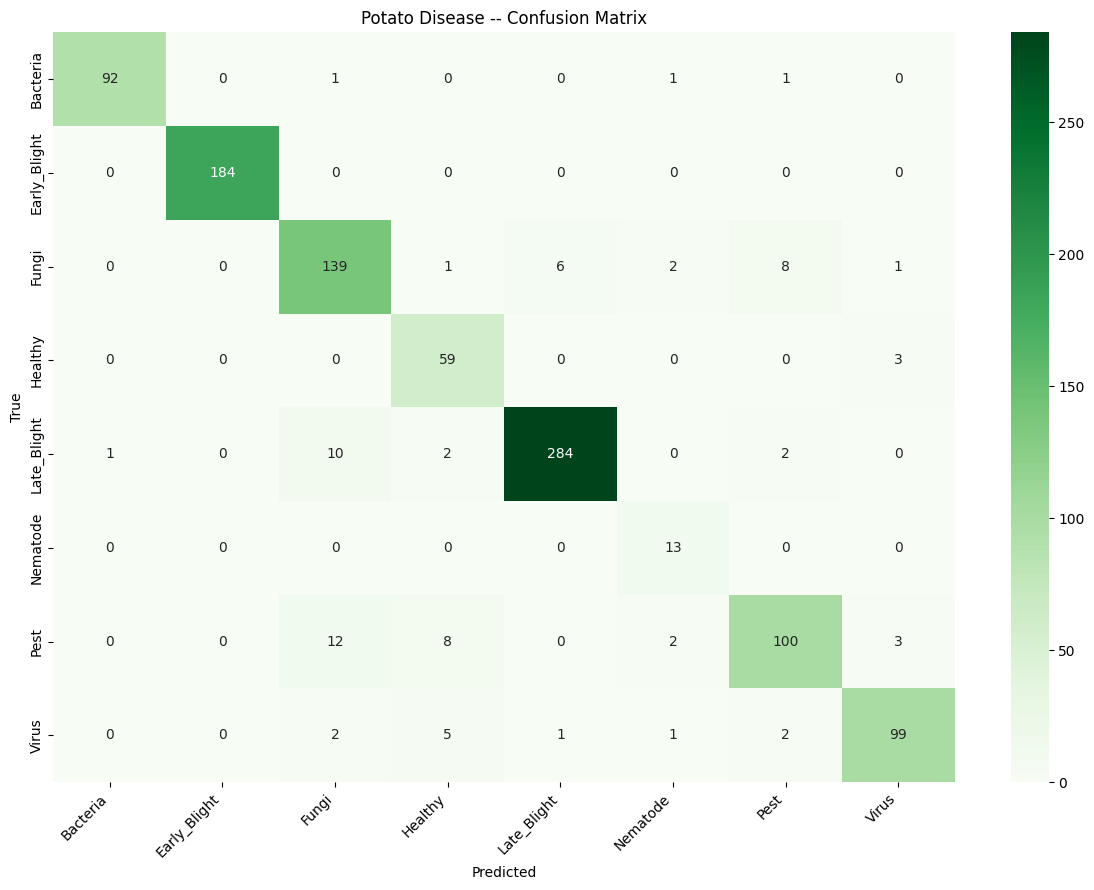

In [9]:
# Evaluation
y_true, y_pred = [], []
for imgs, lbls in val_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Potato Disease -- Confusion Matrix")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig("/kaggle/working/potato_confusion_matrix.png", dpi=150)
plt.show()

In [10]:
DISEASE_NAMES = {
    "Bacteria"      : "Bacteria",
    "Early_Blight"  : "Early Blight",
    "Fungi"         : "Fungi",
    "Healthy"       : "Healthy",
    "Late_Blight"   : "Late Blight",
    "Nematode"      : "Nematode",
    "Pest"          : "Pest",
    "Virus"         : "Virus",
    # "Phytophthora" removed — merged into "Late_Blight" above (same disease)
}

potato_class_map = {}
production_class_names = []
for cls in class_names:
    key = "potato__" + cls.lower()
    production_class_names.append(key)
    potato_class_map[key] = {"crop": "Potato", "disease": DISEASE_NAMES.get(cls, cls)}

with open("/kaggle/working/potato_class_map.json", "w") as f:
    json.dump(potato_class_map, f, indent=2)
with open("/kaggle/working/potato_class_names.json", "w") as f:
    json.dump(production_class_names, f, indent=2)

print("=== potato_class_map.json ===")
print(json.dumps(potato_class_map, indent=2))

files = [
    "/kaggle/working/potato_final.keras",
    "/kaggle/working/potato_best.keras",
    "/kaggle/working/potato_class_map.json",
    "/kaggle/working/potato_class_names.json",
    "/kaggle/working/potato_confusion_matrix.png",
]

print("\n=== Output files ===")
for f in files:
    if os.path.exists(f):
        print(f"  ✅ {os.path.basename(f)} ({os.path.getsize(f)/1024/1024:.1f} MB)")
    else:
        print(f"  ❌ MISSING: {f}")

zip_path = "/kaggle/working/potato_model_package.zip"
with zipfile.ZipFile(zip_path, "w") as zf:
    for f in files:
        if os.path.exists(f):
            zf.write(f, arcname=os.path.basename(f))
print(f"\n✅ Zip saved: {zip_path}")
print("\n⚠️ Do Save Version -> Save & Run All (Commit) now!")

=== potato_class_map.json ===
{
  "potato__bacteria": {
    "crop": "Potato",
    "disease": "Bacteria"
  },
  "potato__early_blight": {
    "crop": "Potato",
    "disease": "Early Blight"
  },
  "potato__fungi": {
    "crop": "Potato",
    "disease": "Fungi"
  },
  "potato__healthy": {
    "crop": "Potato",
    "disease": "Healthy"
  },
  "potato__late_blight": {
    "crop": "Potato",
    "disease": "Late Blight"
  },
  "potato__nematode": {
    "crop": "Potato",
    "disease": "Nematode"
  },
  "potato__pest": {
    "crop": "Potato",
    "disease": "Pest"
  },
  "potato__virus": {
    "crop": "Potato",
    "disease": "Virus"
  }
}

=== Output files ===
  ✅ potato_final.keras (233.7 MB)
  ✅ potato_best.keras (233.7 MB)
  ✅ potato_class_map.json (0.0 MB)
  ✅ potato_class_names.json (0.0 MB)
  ✅ potato_confusion_matrix.png (0.1 MB)

✅ Zip saved: /kaggle/working/potato_model_package.zip

⚠️ Do Save Version -> Save & Run All (Commit) now!
